# Linear classification

The goal of this exercise is to study hard and soft binary linear classification.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Hard linear classification: perceptron algorithm

### Linearly separable data

We start by generating a binary linear classification dataset with 100 examples (50 in each class). You do not need to read the code generating the data, we just randomly select 100 point in $[0, 1]^2$ and assign a label depending on their position.

In [3]:
def create_dataset(n_samples):

    rng = np.random.default_rng()

    X = rng.uniform(0.0, 1.0, (n_samples, 2))

    t = np.array([1 if X[i, 0] + X[i, 1] > 1. else -1 for i in range(n_samples)])

    return X, t

X, t = create_dataset(100)

Let's visualize the training set now in the following cell. Samples of the positive class (t=1) will be represented by blue points, examples of the negative class (t=-1) by orange ones.

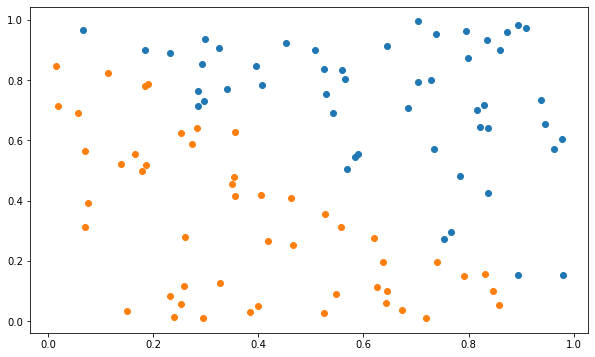

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X[t==1, 0], X[t==1, 1])
plt.scatter(X[t==-1, 0], X[t==-1, 1])
plt.show()

You will now implement the **online version of the Perceptron algorithm** to classify this data set.

As a reminder from the course, we will use a hyperplane $(\mathbf{w}, b)$ to **predict** whether an input $\mathbf{x}_i$ belongs to the positive class (+1) or negative class (-1) using the following function:

$$
    y_i =  \text{sign}( \langle \mathbf{w}, \mathbf{x}_i \rangle + b)
$$

Our goal is to minimize the **mean square error** (MSE) of the hyperplane on the training set:

$$
    L(\mathbf{w}, b) = \frac{1}{N} \, \sum_{i=1}^N (t_i - y_i)^2
$$

With the heuristic application of gradient descent to this loss function, we obtain the **delta learning rule**:

$$
    \Delta \mathbf{w} = \eta \, \sum_{i=1}^N (t_i - y_i) \, \mathbf{x}_i
$$

$$
    \Delta b = \eta \, \sum_{i=1}^N (t_i - y_i)
$$

The online version of the Perceptron is given by the following algorithm:

$\text{Initialize the weight vector } \mathbf{w} \text{ and the bias } b.$

$\textbf{for } M \text{epochs:}$

$\qquad \textbf{forall } \text{examples } (\mathbf{x}_i, t_i) :$

$\qquad \qquad y_i =  \text{sign}( \langle \mathbf{w}, \mathbf{x}_i \rangle + b)$

$\qquad \qquad \mathbf{w} \gets \mathbf{w} + \eta \, (t_i - y_i) \, \mathbf{x}_i$

$\qquad \qquad b \gets b + \eta \, (t_i - y_i)$


**Q:** Implement the algorithm based on the linear regression algorithm of exercise 3. The only difference is that the weight vector is now a vector... You will need to use `np.dot`. Use 20 epochs and a learning rate of 0.01 at first, but you can vary it later. Initialize the weight vector and the bias to 0. Make a plot of the mse during training.

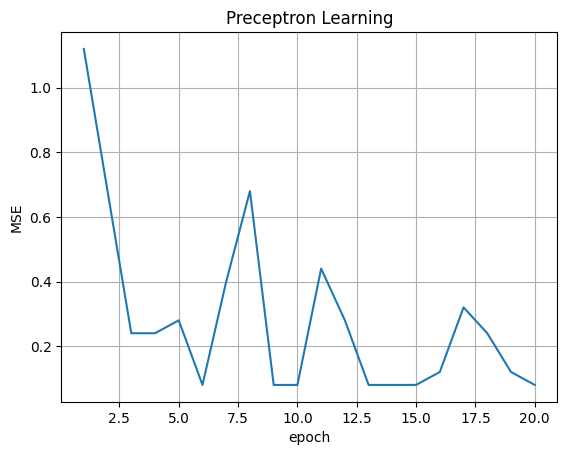

final w =  [0.16408007 0.15196863]
final b =  -0.16
final mse =  0.08


In [7]:
from os import error
import numpy as np
import matplotlib.pyplot as plt

eta = 0.01
M = 20

w = np.zeros(2) # a array fulfiled with 0, 2 weights
b = 0

mse_history = []


for epoch in range(M):
  for i in range(len(X)):

    z = np.dot(w, X[i]) + b  # 计算线性组合， z = w[1]x[i1] + w[2]x[i2] + b

    y = 1 if z >=0 else -1 # 接着根据z的正负 去判断 z 的类别

    error = t[i] - y #最后 根据真实类别（target） 来判断误差， 若error=0 则继续处理下一个样本，否则更新w和b参数

    w = w + eta * error * X[i]

    b = b + eta * error

  z_all = X @ w + b
  y_pred = np.where(z_all >= 0, 1, -1)
  mse = np.mean((t - y_pred) ** 2)
  mse_history.append(mse)



plt.plot(range(1, M+1), mse_history)

plt.xlabel('epoch')
plt.ylabel('MSE')
plt.title('Preceptron Learning')

plt.grid(True)
plt.show()

print('final w = ',w)
print('final b = ', b)
print('final mse = ', mse_history[-1])



**Q:** Visualize the hyperplane. If we call $x_0$ and $x_1$ the two coordinates of the inputs, the equation of the hyperplane is:

$$w_0 \, x_0 + w_1 \, x_1 + b = 0$$

which takes the form:

$$x_1 = - (w_0 \, x_0 + b) / w_1$$

You just need to draw a line between the two extremities of the hyperplane, for example between 0 and 1 or between `X[:, 0].min()` and `X[:, 0].max()`.

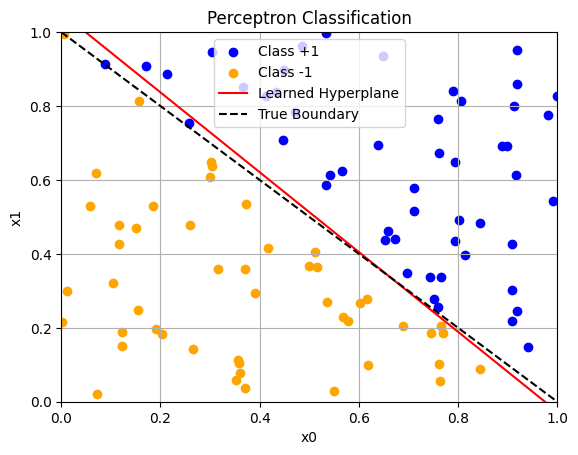

In [8]:
plt.scatter(X[t == 1, 0], X[t == 1, 1],
            color = "blue", label = "Class +1")

plt.scatter(X[t == -1, 0], X[t == -1, 1],
            color="orange", label="Class -1")

# 确定横坐标的两个端点
x0 = np.array([0, 1])

# 计算超平面对应的纵坐标
x1 = -(w[0] * x0 + b) / w[1]

plt.plot(x0, x1, color="red",
         label="Learned Hyperplane") # draw the hyperplane

# 绘制真实分类边界（额外用于比较）
plt.plot(x0, 1 - x0, "k--",
         label="True Boundary")


plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Perceptron Classification")

plt.legend()
plt.grid(True)
plt.show()


Before going further, let's track the evolution of the classification error during learning, defined as the fraction of incorrectly classified examples during one epoch:

$$
    \epsilon = \frac{\text{Number of misclassifications}}{\text{Number of samples}}
$$

**Q:** Modify your algorithm to compute the training error and the MSE loss for each epoch. How do the training error and loss evolve during learning? Do you really need both?

*Tips:* When iterating over each training example, you will need to increment a counter for misclassifications when your prediction `y_i` is different from `t[i]` (use `!=` for "not equal").

**Q:** Now is the time to play with the hyperparameters:
    
1. Vary the learning rate `eta` between extreme values (from 0.000001 to 100.0).
2. Increase the number of epochs `nb_epochs`.

What does it change?    

**Q:** Change the initial value of the weight vector $\mathbf{w}$ to something different from 0 (e.g. [1, -1], [-5, 5], etc). What does it change? Vary the learning rate again and conclude on the importance of weight initialization.

### Non-linearly separable data

The generated dataset was obviously linearly separable, because you found a linear hyperplane able to classify it... Let's now see what happens when you apply your algorithm on a non-linearly separable dataset. It is basically the same method as before, except that we add one outlier at the end.

In [ ]:
def create_dataset(n_samples):

    rng = np.random.default_rng()
    X = rng.uniform(0.0, 1.0, (n_samples-1, 2))
    t = np.array([1 if X[i, 0] + X[i, 1] > 1. else -1 for i in range(n_samples-1)])

    # Outlier
    X = np.append(X, np.array([0.1, 0.1]).reshape((1, 2)), axis=0)
    t = np.append(t, [1])
    return X, t

X, t = create_dataset(100)

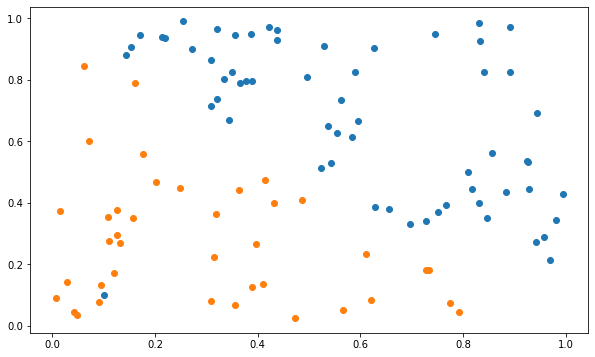

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X[t==1, 0], X[t==1, 1])
plt.scatter(X[t==-1, 0], X[t==-1, 1])
plt.show()

**Q:** Apply your online Perceptron algorithm (with default values: `eta = 0.1`, `nb_epochs = 20`,$\mathbf{w}$ and $b$ initialized to 0) to the non-linear data. At the end of learning, compute the final error on the training set. What do you observe? Is it a satisfying result? Does it get better when you change the learning rate or weight initialization?

## Soft linear classification: logistic regression

Let's now see whether **logistic regression** helps us with outliers. The following cell implements the logistic function:

$$\sigma(x) = \dfrac{1}{1 + e^{-x}}$$

In [ ]:
def logistic(x):
    return 1. / (1 + np.exp(-x))

In logistic regression, the prediction $y = \sigma(w \, x + b)$ represents the probability of belonging to the positive class. If $y>0.5$, we can say that the example belongs to the positive class.

As seen in the course, there is absolutely no difference in the learning algorithm apart from using the logistic function instead of the sign. One thing to take care of, though, is that the targets $t_i$ should be 0 and 1 in the logistic regression algorithm, while they are -1 and 1 in the current vector $\mathbf{t}$. The following cell transforms the array `t` to match the output of the logistic function.

In [ ]:
t[t==-1] = 0

**Q:** Implement the logistic regression algorithm on the non-linear data. When computing the error, you will need to predict the class based on the probability $y$. What do you observe? Conclude.